# 3 · Train, evaluate and export the models

Uses the search result from notebook 2 (`data/models/hyperparameters.json`, or defaults if it does not exist yet) and

1. evaluates each model **leave-one-sausage-out**: train on four sausages, score on the fifth;
2. saves one model per fold (`data/models/folds/`). The demonstrator replays a sausage with the model that never saw it;
3. trains the final models on all annotated sausages (`data/models/final/`);
4. writes `manifest.json` and `metrics.json`, which the demonstrator's evaluation panel shows.

It also checks the models on the **unannotated series 2** (summer → spring): phases can only advance in time, so the
predicted phase should rise there too. A model that learned the season instead of the ripening runs backwards
(details and the comparison of feature sets: notebook 04).

`FEATURE_SET` must match the one used in notebook 2. `LIMIT_SIZE` caps the Random Forest (100 trees, depth 10). An unlimited forest on this data grows to hundreds of MB.
**Train with the same scikit-learn version the demo laptop runs**, because model files are not portable across versions.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))  # project root, so ml_core is importable
import glob
import matplotlib.pyplot as plt
import pandas as pd
from ml_core import data
from ml_core.training import (AUGMENTATION, DEFAULT_FEATURE_SET, augment_temperature, build_steps, load_hyperparameters,
                              load_windows, metrics_table, predict_progression, train_and_evaluate, training_params)

In [2]:
CONVERTED_DIR = data.CONVERTED_DIR
MODELS_DIR = data.MODELS_DIR
WINDOW_SIZE, STRIDE = 10, 2
FEATURE_SET = DEFAULT_FEATURE_SET   # see FEATURE_SETS in ml_core/training.py
AUGMENT = False                     # True: augment temperature features in the training data (see notebook 04)
LIMIT_SIZE = True
FOLD_MODELS = True
QUICK = False
N_JOBS = -1          # worker processes for folds (-1 = all cores); lower it if RAM runs short

In [3]:
windows = load_windows(CONVERTED_DIR, window_size=WINDOW_SIZE, stride=STRIDE)
unannotated = None
if glob.glob(os.path.join(CONVERTED_DIR, "series_2_*.csv")):
    unannotated = load_windows(CONVERTED_DIR, "series_2_*.csv", WINDOW_SIZE, STRIDE, annotated=False, classes=windows.classes)
windows.summary()

series_1_sausage_1: 41,462 rows → 20,727 windows
series_1_sausage_2: 41,479 rows → 20,735 windows
series_1_sausage_3: 41,468 rows → 20,730 windows


series_1_sausage_4: 41,472 rows → 20,732 windows
series_1_sausage_5: 41,465 rows → 20,728 windows


series_2_sausage_1: 79,919 rows → 39,955 windows
series_2_sausage_2: 79,903 rows → 39,947 windows
series_2_sausage_3: 79,915 rows → 39,953 windows
series_2_sausage_4: 79,920 rows → 39,956 windows
series_2_sausage_5: 79,930 rows → 39,961 windows


,recording,rows,windows,from,to,Umroetung,Reifung Phase 1,Reifung Phase 2
0,series_1_sausage_1,41462,20727,2023-03-30 00:33:38.051909+00:00,2023-08-02 23:56:34.268438+00:00,7304,8116,5307
1,series_1_sausage_2,41479,20735,2023-03-30 00:33:38.051909+00:00,2023-08-02 23:43:26.013334+00:00,7309,8120,5306
2,series_1_sausage_3,41468,20730,2023-03-30 00:38:00.000000+00:00,2023-08-02 23:58:00.000000+00:00,7307,8118,5305
3,series_1_sausage_4,41472,20732,2023-03-30 00:37:55.818346+00:00,2023-08-02 23:55:25.481812+00:00,7308,8120,5304
4,series_1_sausage_5,41465,20728,2023-03-30 00:33:38.051909+00:00,2023-08-02 23:49:39.000000+00:00,7307,8117,5304


In [4]:
metrics = train_and_evaluate(windows, MODELS_DIR, FEATURE_SET, unannotated, augmentation=AUGMENTATION if AUGMENT else None,
                             limit_size=LIMIT_SIZE, fold_models=FOLD_MODELS, quick=QUICK, n_jobs=N_JOBS)

Feature set: temperature_difference (lse01_conductivity, lse01_moisture, lse01_temperature_diff, ltcfs_temperature_diff)
Hyperparameters: hyperparameters.json from 2026-11-25

=== Logistic Regression ===  {'C': 100, 'class_weight': 'balanced', 'l1_ratio': 0, 'max_iter': 1000, 'solver': 'liblinear'}


  without series_1_sausage_1: balanced acc 0.603 (40.8 s)
  without series_1_sausage_2: balanced acc 0.781 (19.3 s)
  without series_1_sausage_3: balanced acc 0.618 (22.8 s)
  without series_1_sausage_4: balanced acc 0.789 (24.9 s)
  without series_1_sausage_5: balanced acc 0.775 (25.7 s)
  all sausages: fitted (23.1 s)


  mean balanced acc 0.713 · 3.8 ms per prediction · 0.0 MB · series 2 phase order ρ +0.80

=== Random Forest ===  {'bootstrap': True, 'class_weight': 'balanced_subsample', 'criterion': 'gini', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 100}


  without series_1_sausage_1: balanced acc 0.605 (6.3 s)


  without series_1_sausage_2: balanced acc 0.793 (6.4 s)
  without series_1_sausage_3: balanced acc 0.807 (6.2 s)
  without series_1_sausage_4: balanced acc 0.577 (6.1 s)


  without series_1_sausage_5: balanced acc 0.746 (6.3 s)


  all sausages: fitted (7.8 s)


  mean balanced acc 0.706 · 9.3 ms per prediction · 4.4 MB · series 2 phase order ρ +0.77

=== MLP (neural net) ===  {'activation': 'tanh', 'alpha': 0.001, 'batch_size': 32, 'early_stopping': True, 'hidden_layer_sizes': [64, 32], 'learning_rate_init': 0.0003, 'max_iter': 500, 'validation_fraction': 0.15}


  without series_1_sausage_1: balanced acc 0.611 (74.7 s)


  without series_1_sausage_2: balanced acc 0.710 (121.7 s)
  without series_1_sausage_3: balanced acc 0.743 (102.0 s)
  without series_1_sausage_4: balanced acc 0.702 (62.6 s)
  without series_1_sausage_5: balanced acc 0.642 (48.7 s)
  all sausages: fitted (100.1 s)


  mean balanced acc 0.682 · 3.7 ms per prediction · 0.1 MB · series 2 phase order ρ +0.81

Wrote models, manifest.json and metrics.json to F:\_Data\Uni\MA_Project\masterproject-lorawan-demonstrator\data\models


## Results (mean ± std over the held-out sausages)

In [5]:
metrics_table(metrics)

,balanced acc,macro-F1,accuracy,ms / prediction,size (MB),fit all data (s),series 2: phase order ρ,series 2: backwards share
model,,,,,,,,
Logistic Regression,0.713 ± 0.084,0.685 ± 0.103,0.713 ± 0.094,3.80,0.01,23.1,0.796,0.695
Random Forest,0.706 ± 0.096,0.697 ± 0.111,0.703 ± 0.112,9.31,4.38,7.8,0.767,0.634
MLP (neural net),0.682 ± 0.048,0.668 ± 0.068,0.687 ± 0.074,3.71,0.11,100.1,0.809,0.687


In [6]:
# balanced accuracy per held-out sausage
pd.DataFrame({m["name"]: {f["held_out"]: round(f["balanced_accuracy"], 3) for f in m["folds"]}
              for m in metrics["models"].values()})

,Logistic Regression,Random Forest,MLP (neural net)
series_1_sausage_1,0.603,0.605,0.611
series_1_sausage_2,0.781,0.793,0.710
series_1_sausage_3,0.618,0.807,0.743
series_1_sausage_4,0.789,0.577,0.702
series_1_sausage_5,0.775,0.746,0.642


In [7]:
# confusion matrices, row-normalised (rows: annotation, columns: prediction)
for m in metrics["models"].values():
    cm = pd.DataFrame(m["confusion_matrix"], index=metrics["classes"], columns=metrics["classes"])
    print(m["name"])
    display((cm.div(cm.sum(axis=1), axis=0) * 100).round(1))

Logistic Regression


,Umroetung,Reifung Phase 1,Reifung Phase 2
Umroetung,88.5,9.7,1.8
Reifung Phase 1,8.0,59.1,32.9
Reifung Phase 2,0.0,33.6,66.4


Random Forest


,Umroetung,Reifung Phase 1,Reifung Phase 2
Umroetung,88.6,11.4,0.0
Reifung Phase 1,14.6,56.0,29.4
Reifung Phase 2,0.2,32.6,67.1


MLP (neural net)


,Umroetung,Reifung Phase 1,Reifung Phase 2
Umroetung,89.1,10.8,0.1
Reifung Phase 1,11.2,56.8,32.0
Reifung Phase 2,0.6,40.7,58.7


In [8]:
# how often two models give the same label on held-out windows
pd.Series(metrics["agreement_on_held_out"]).round(3)

logreg|rf     0.780
logreg|mlp    0.779
rf|mlp        0.844
dtype: float64

## Plausibility on the unannotated series 2

Predicted phase over time (smoothed over one day). Plausible: a staircase going up. A model that follows the
temperature instead goes down in autumn and winter. ρ in the table above: +1 = phases only advance.

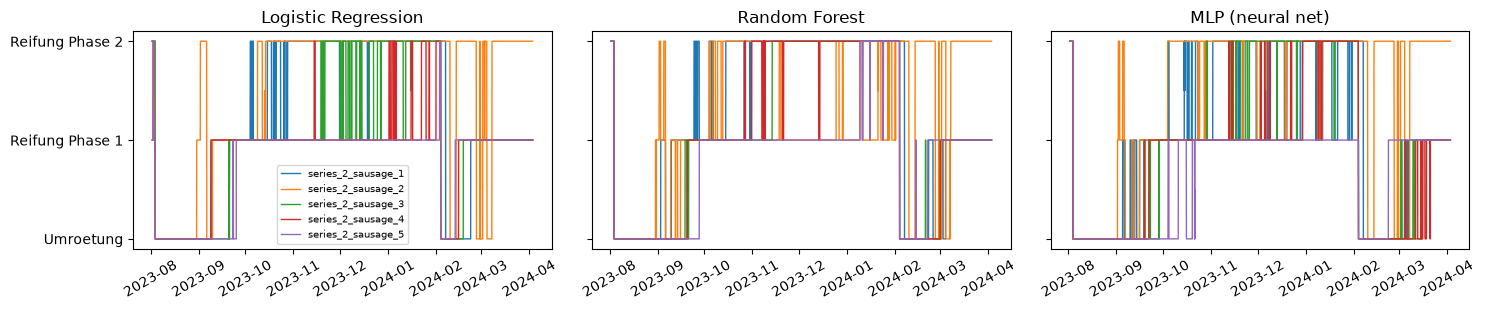

In [9]:
if unannotated is not None:
    params = load_hyperparameters(MODELS_DIR)[0]
    w, u = windows.select(FEATURE_SET), unannotated.select(FEATURE_SET)
    X, y, _ = w.stack()
    if AUGMENT:
        X, y = augment_temperature(X, y)
    fig, axes = plt.subplots(1, len(metrics["models"]), figsize=(15, 3.2), sharey=True)
    for ax, key in zip(axes, metrics["models"]):
        steps = build_steps(key, training_params(key, params[key], LIMIT_SIZE, QUICK)).fit(X, y)
        for rec, s in predict_progression(steps, u, w.classes).items():
            ax.plot(s.index, s.values, label=rec, lw=1)
        ax.set(title=metrics["models"][key]["name"], yticks=range(len(w.classes)), yticklabels=w.classes)
        ax.tick_params(axis="x", rotation=30)
    axes[0].legend(fontsize=7)
    plt.tight_layout()
    plt.show()

**Next:** start the demonstrator (`scripts/start_demo.ps1`). It loads the models from `data/models/`.
Read the scores with care: all annotated sausages come from one curing run.